# 14 · Synchronization worked example

Illustrate ET/Eyeball alignment with a figure and lag-search animation. Set input paths with `DATA_ROOT`, `PID` and `VISIT` below; only the output uses `figures_cache_root`. Saved mappings and earlier figures are not required.


In [1]:
import io
import sys
from pathlib import Path

sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import Image, display

PROJECT_ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                    if (p / 'helpers').is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from helpers.sync_quality import et_eyeball_alignment as alignment
from helpers.lsl_et_sync import offset as core
from helpers.project_config import load_project_config

CONFIG = load_project_config(PROJECT_ROOT / 'config.json')
OUTPUT_DIR = CONFIG.path('paths', 'figures_cache_root') / '14_sync_example'
DPI = 600
FIGURE_SIZE_MM = (180, 150)
FONT_SIZES = dict(title=9, label=8, tick=8, note=7, legend=6.5, trial=7)

DATA_ROOT = Path('E:/ImBrAid/Data')
PID, VISIT = 'A7G5SM', 'VX'
ET_RECORDING = DATA_ROOT / 'time_shifted' / PID / 'ET' / f'{PID}_{VISIT}_et_raw'
PUPIL_CSV = DATA_ROOT / 'processed/Eyeball_Videos/pupil_sizes' / f'{PID}_{VISIT}_eyeball_video_pupil_sizes.csv'

WINDOW_S, STEP_S, SAMPLE_HZ, COARSE_HZ = 90.0, 45.0, 20.0, 5.0
SEARCH_RADIUS_S, MAX_GAP_S, MIN_R, MIN_MARGIN = 15.0, 0.25, 0.25, 0.02
EXCERPT_S, DETAIL_S, TRIAL_SPACING_S = 20.0, 5.0, 0.5
GIF_RADIUS_S, GIF_FRAME_MS, GIF_HOLD_MS = 0.5, 170, 1800
COLORS = dict(et='#18334D', video='#D97A36', selected='#4477AA', muted='#60758A')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'axes.titlesize': 13, 'axes.labelsize': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
TEXT = {
    'A': {
        'title': 'a  Before correction:\n    native clocks',
        'x': 'Time relative to window center (s)', 'y': 'Standardized pupil feature (z)',
        'note': '{excerpt:g} s envelope: r = {r_before:.3f}',
    },
    'B': {
        'title': 'b  Slide the pupil signal\n    and score each lag',
        'x': 'Time in the fixed {detail:g} s detail (s)', 'y': '',
        'trial': 'd = {d:.3f} s; r = {r:.3f}{suffix}',
        'grid_suffix': ' [peak]',
    },
    'C': {
        'title': 'c  Find the local\n    correlation peak',
        'x': 'Trial offset (s):\nVideo √pupil area - ET pupil diameter', 'y': 'Overlap-normalized correlation',
        'note': '{window:g} s window: peak r = {peak_r:.3f}\nGrid {d_grid:.3f} s; refined {d_refined:.3f} s',
    },
    'D': {
        'title': 'd  Fit offset and linear clock drift',
        'x': 'ET recording time (min)', 'y': 'Estimated eyeball video - ET offset (ms)',
        'note': 'a = {a:.6f} s; b = {b:.10f}\nDrift {drift:.2f} ppm; inlier P95 {p95:.2f} ms\n{n_good} accepted; {n_inliers} inliers; {n_excluded} excluded',
    },
    'E': {
        'title': 'e  Apply the clock map: same envelope',
        'x': 'Time relative to window center (s)', 'y': 'Standardized pupil feature (z)',
        'note': 't_ET = (t_video - a) / b; r = {r_after:.3f}',
    },
    'legend': {
        'et': 'ET pupil diameter', 'before': 'Video √pupil area',
        'after': 'Video √pupil area',
        'coarse': 'Coarse offset: {prior:.3f} s', 'refined': 'Refined peak: {d_refined:.3f} s',
        'threshold': 'Minimum r: {min_r:g}', 'model': 'Robust affine fit',
        'windows': 'Accepted lags', 'midpoint': 'Example window',
    },
    'gif': {
        'title': 'Slide the eyeball video, then score the match',
        'subtitle': 'Real {pid}/{visit} data · {n_scan} of {n_trials} grid candidates · each r uses the full {window:g} s window',
        'x': 'Time within a fixed {detail:g} s detail (s)', 'y': 'Normalized signal feature',
        'et': 'ET feature: fixed', 'video': 'Video feature: moved for each trial',
        'trial': 'Trial {i:02d}/{n_scan}: d = {d:.6f} s  →  r = {r:.3f}{suffix}',
        'grid_suffix': '   [highest grid score]',
        'final': 'Select d = {d_grid:.6f} s; quadratic peak refinement → {d_refined:.6f} s',
        'footer': 'r(d) = corr[ET(t), video(t + d)]  ·  {hz:g} Hz grid  ·  no synthetic signals',
    },
}
INFO = dict(pid=PID, visit=VISIT, window=WINDOW_S, step=STEP_S, hz=SAMPLE_HZ,
            excerpt=EXCERPT_S, detail=DETAIL_S, min_r=MIN_R)
def label(group, key, **values):
    return TEXT[group][key].format(**(INFO | values))


In [3]:
et, video, et_audit, video_audit = alignment._load_sources(ET_RECORDING, PUPIL_CSV)
assert not (et_audit['nonincreasing_timestamps'] or video_audit['nonincreasing_timestamps'])
priors = alignment._coarse_priors(et, video, et_audit, video_audit, COARSE_HZ)
settings = dict(window_s=WINDOW_S, step_s=STEP_S, sample_hz=SAMPLE_HZ, max_gap_s=MAX_GAP_S,
                local_residual_search_radius_s=SEARCH_RADIUS_S,
                min_peak_correlation=MIN_R, min_peak_margin=MIN_MARGIN)
fit = alignment._best_fit(et, video, alignment.PUPIL_GROUPS, priors, settings)
a, b, prior = fit['intercept_s'], fit['scale'], fit['prior_offset_s']
windows = pd.DataFrame(fit['windows'])
et_time = et['timestamp'].to_numpy(float)
video_time = video.index.view('int64').astype(float) / 1e9
start = max(et_time.min(), video_time.min() - prior)
end = min(et_time.max(), video_time.max() - prior)
centers = np.arange(start + WINDOW_S / 2, end - WINDOW_S / 2 + STEP_S / 2, STEP_S)
center = centers[np.argmin(abs(centers - (et_time.min() + et_time.max()) / 2))]
grid = np.arange(center - WINDOW_S / 2, center + WINDOW_S / 2, 1 / SAMPLE_HZ)

def prepare(times, values):
    values, valid = core._interpolate_without_long_gaps(times, values, grid, MAX_GAP_S)
    return core._normalise_window(values, valid)
et_valid = et[['timestamp', 'left-pupil']].dropna()
video_valid = video[['left-pupil']].dropna()
et_feature, et_mask = prepare(et_valid['timestamp'].to_numpy(float), et_valid['left-pupil'].to_numpy(float))
video_feature, video_mask = prepare(video_valid.index.view('int64').astype(float) / 1e9 - prior,
                                    video_valid['left-pupil'].to_numpy(float))
lags, scores, overlap = core._masked_normalised_vector_correlation(
    et_feature[None, :], video_feature[None, :], et_mask[None, :], video_mask[None, :])
search = (abs(lags) <= SEARCH_RADIUS_S * SAMPLE_HZ) & np.isfinite(scores) & (overlap >= core.MIN_WINDOW_OVERLAP_S * SAMPLE_HZ)
best = np.flatnonzero(search)[np.argmax(scores[search])]
best_lag = int(lags[best])
local = core._local_group_offset(et, video, ['left-pupil'], 'left-pupil', center, prior,
                                 WINDOW_S, SEARCH_RADIUS_S, MAX_GAP_S, {'left-pupil': SAMPLE_HZ})
d_grid, d_refined = prior - best_lag / SAMPLE_HZ, local['offset_s']
trial_lags = best_lag + np.array([1, 0, -1]) * round(TRIAL_SPACING_S * SAMPLE_HZ)
def score(lag):
    return scores[np.flatnonzero(lags == lag)[0]]
def shifted(lag):
    source = np.arange(len(video_feature)) - int(lag)
    valid = (source >= 0) & (source < len(video_feature))
    result = np.full(len(video_feature), np.nan)
    result[valid] = np.where(video_mask[source[valid]], video_feature[source[valid]], np.nan)
    return result

detail = abs(grid - center) <= DETAIL_S / 2
et_detail = np.where(et_mask, et_feature, np.nan)[detail]
trial_features = np.array([shifted(lag)[detail] for lag in trial_lags])
shown = np.concatenate([et_detail, trial_features.ravel()])
shown = shown[np.isfinite(shown)]
matching_ylim = (shown.min() - .08 * np.ptp(shown), shown.max() + .23 * np.ptp(shown))

mapped_time = (video_time - a) / b
excerpt_time = np.arange(center - EXCERPT_S / 2, center + EXCERPT_S / 2, 1 / SAMPLE_HZ)
interpolate = alignment._interpolate_with_gap_mask
et_values, video_values = et['left-pupil'].to_numpy(float), video['left-pupil'].to_numpy(float)
et_excerpt = interpolate(et_time, et_values, excerpt_time, MAX_GAP_S)
video_before = interpolate(video_time, video_values, excerpt_time, MAX_GAP_S)
video_after = interpolate(mapped_time, video_values, excerpt_time, MAX_GAP_S)
et_scale = et_values[(abs(et_time - center) <= WINDOW_S / 2) & np.isfinite(et_values)]
video_scale = video_values[(abs(mapped_time - center) <= WINDOW_S / 2) & np.isfinite(video_values)]
et_z = (et_excerpt - et_scale.mean()) / et_scale.std()
video_before_z = (video_before - video_scale.mean()) / video_scale.std()
video_after_z = (video_after - video_scale.mean()) / video_scale.std()
def correlation(first, second):
    valid = np.isfinite(first) & np.isfinite(second)
    return np.corrcoef(first[valid], second[valid])[0, 1]
midpoint = windows.iloc[np.argmin(abs(windows['center_et_s'] - center))]
INFO.update(start=center-WINDOW_S/2, end=center+WINDOW_S/2, a=a, b=b, prior=prior,
            drift=(b-1)*1e6, p95=fit['fit_residual_p95_s']*1000,
            n_good=fit['n_good_windows'], n_inliers=fit['fit_inliers'],
            n_excluded=fit['n_good_windows']-fit['fit_inliers'], n_trials=int(search.sum()),
            d_grid=d_grid, d_refined=d_refined, peak_r=score(best_lag),
            r_before=correlation(et_excerpt, video_before), r_after=correlation(et_excerpt, video_after))


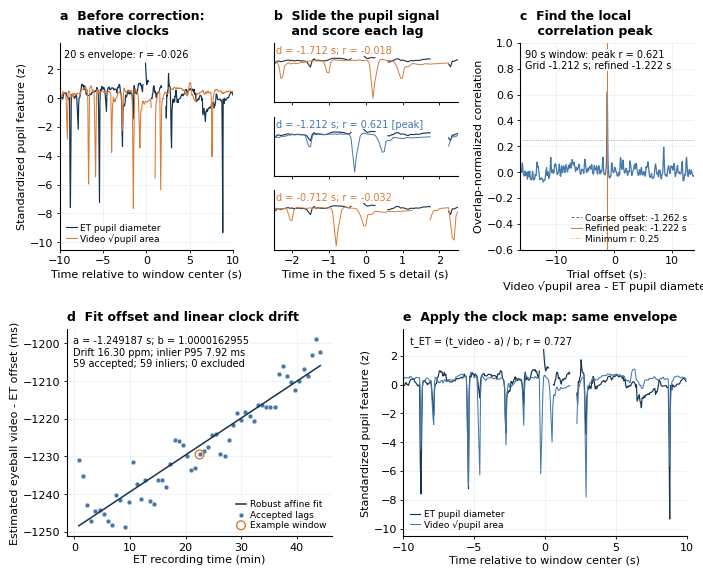

In [4]:
navy, orange, teal, muted = (COLORS[k] for k in ('et', 'video', 'selected', 'muted'))
fig = plt.figure(figsize=np.array(FIGURE_SIZE_MM) / 25.4, facecolor='white')
axes = {k: fig.add_axes(box) for k, box in {
    'A': [.080, .565, .245, .350], 'C': [.730, .565, .245, .350],
    'D': [.090, .080, .375, .350], 'E': [.565, .080, .400, .350]}.items()}
for key, ax in axes.items():
    ax.set_title(label(key, 'title'), loc='left', weight='bold', pad=6, fontsize=FONT_SIZES['title'])
    ax.set_xlabel(label(key, 'x'), fontsize=FONT_SIZES['label'], labelpad=2)
    ax.set_ylabel(label(key, 'y'), fontsize=FONT_SIZES['label'], labelpad=2)
    ax.tick_params(labelsize=FONT_SIZES['tick'], length=2.5, width=.6, pad=2)
    ax.locator_params(axis='x', nbins=5)
    ax.grid(True, color='#E5EBF0', lw=.4)
    ax.set_axisbelow(True)
    ax.text(.025, .97, label(key, 'note'), transform=ax.transAxes, va='top',
            fontsize=FONT_SIZES['note'], bbox=dict(fc='white', ec='none', alpha=.9, pad=.3))
for key, values, color, legend in [('A', video_before_z, orange, 'before'), ('E', video_after_z, teal, 'after')]:
    ax = axes[key]
    ax.plot(excerpt_time-center, et_z, color=navy, lw=.85, label=label('legend', 'et'))
    ax.plot(excerpt_time-center, values, color=color, lw=.75, label=label('legend', legend))
    ax.set_xlim(-EXCERPT_S/2, EXCERPT_S/2)
    ax.set_xticks(np.linspace(-EXCERPT_S/2, EXCERPT_S/2, 5))
    ax.legend(loc='lower left', fontsize=FONT_SIZES['legend'], handlelength=1.2,
              handletextpad=.35, borderpad=.2, labelspacing=.15, frameon=False)
limits = np.concatenate([et_z, video_before_z, video_after_z])
limits = limits[np.isfinite(limits)]
for key in ('A', 'E'):
    axes[key].set_ylim(limits.min()-.10*np.ptp(limits), limits.max()+.12*np.ptp(limits))

for i, lag in enumerate(trial_lags):
    ax = fig.add_axes([.382, .815-.125*i, .260, .100])
    if i == 0:
        ax.set_title(label('B', 'title'), loc='left', weight='bold', pad=6, fontsize=FONT_SIZES['title'])
    color = teal if lag == best_lag else orange
    ax.plot(grid[detail]-center, et_detail, color=navy, lw=.8)
    ax.plot(grid[detail]-center, trial_features[i], color=color, lw=.7)
    ax.set_ylim(*matching_ylim)
    ax.set_xlim(-DETAIL_S/2, DETAIL_S/2)
    ax.set_yticks([])
    ax.tick_params(labelsize=FONT_SIZES['tick'], length=2.5, width=.6, pad=2)
    suffix = label('B', 'grid_suffix') if lag == best_lag else ''
    ax.text(.015, .96, label('B', 'trial', d=prior-lag/SAMPLE_HZ, r=score(lag), suffix=suffix),
            transform=ax.transAxes, va='top', fontsize=FONT_SIZES['trial'], color=color,
            bbox=dict(fc='white', ec='none', alpha=.9, pad=.3))
    if i < 2:
        ax.tick_params(labelbottom=False)
    else:
        ax.set_xlabel(label('B', 'x'), fontsize=FONT_SIZES['label'], labelpad=2)
    if i == 1:
        ax.set_ylabel(label('B', 'y'), fontsize=FONT_SIZES['label'])

ax = axes['C']
trial_offsets = prior-lags[search]/SAMPLE_HZ
order = np.argsort(trial_offsets)
ax.plot(trial_offsets[order], scores[search][order], color=teal, lw=.9)
ax.axvline(prior, color=muted, ls='--', lw=.65, label=label('legend', 'coarse'))
ax.axvline(d_refined, color=orange, lw=.75, label=label('legend', 'refined'))
ax.axhline(MIN_R, color='#999999', ls=':', lw=.6, label=label('legend', 'threshold'))
ax.set_xlim(prior-SEARCH_RADIUS_S, prior+SEARCH_RADIUS_S)
ax.set_ylim(-.6, 1)
ax.legend(loc='lower right', fontsize=FONT_SIZES['legend'], handlelength=1.2,
          handletextpad=.35, borderpad=.2, labelspacing=.15, frameon=False)
ax = axes['D']
x = windows['center_et_s'].to_numpy(float)
ax.plot(x/60, (a+(b-1)*x)*1000, color=navy, lw=1.1, label=label('legend', 'model'))
ax.scatter(x/60, windows['offset_s']*1000, s=12, color=teal, edgecolor='white', lw=.3,
           label=label('legend', 'windows'))
ax.scatter([midpoint['center_et_s']/60], [midpoint['offset_s']*1000], s=40,
           facecolors='none', edgecolors=orange, lw=1.0, label=label('legend', 'midpoint'))
ax.legend(loc='lower right', fontsize=FONT_SIZES['legend'], handlelength=1.2,
          handletextpad=.35, borderpad=.2, labelspacing=.15, frameon=False)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(OUTPUT_DIR / f'{PID}_{VISIT}_sync_example.png', dpi=max(300, DPI), facecolor='white')
fig.savefig(OUTPUT_DIR / f'{PID}_{VISIT}_sync_example.svg', dpi=max(300, DPI), facecolor='white')
display(fig)
plt.close(fig)


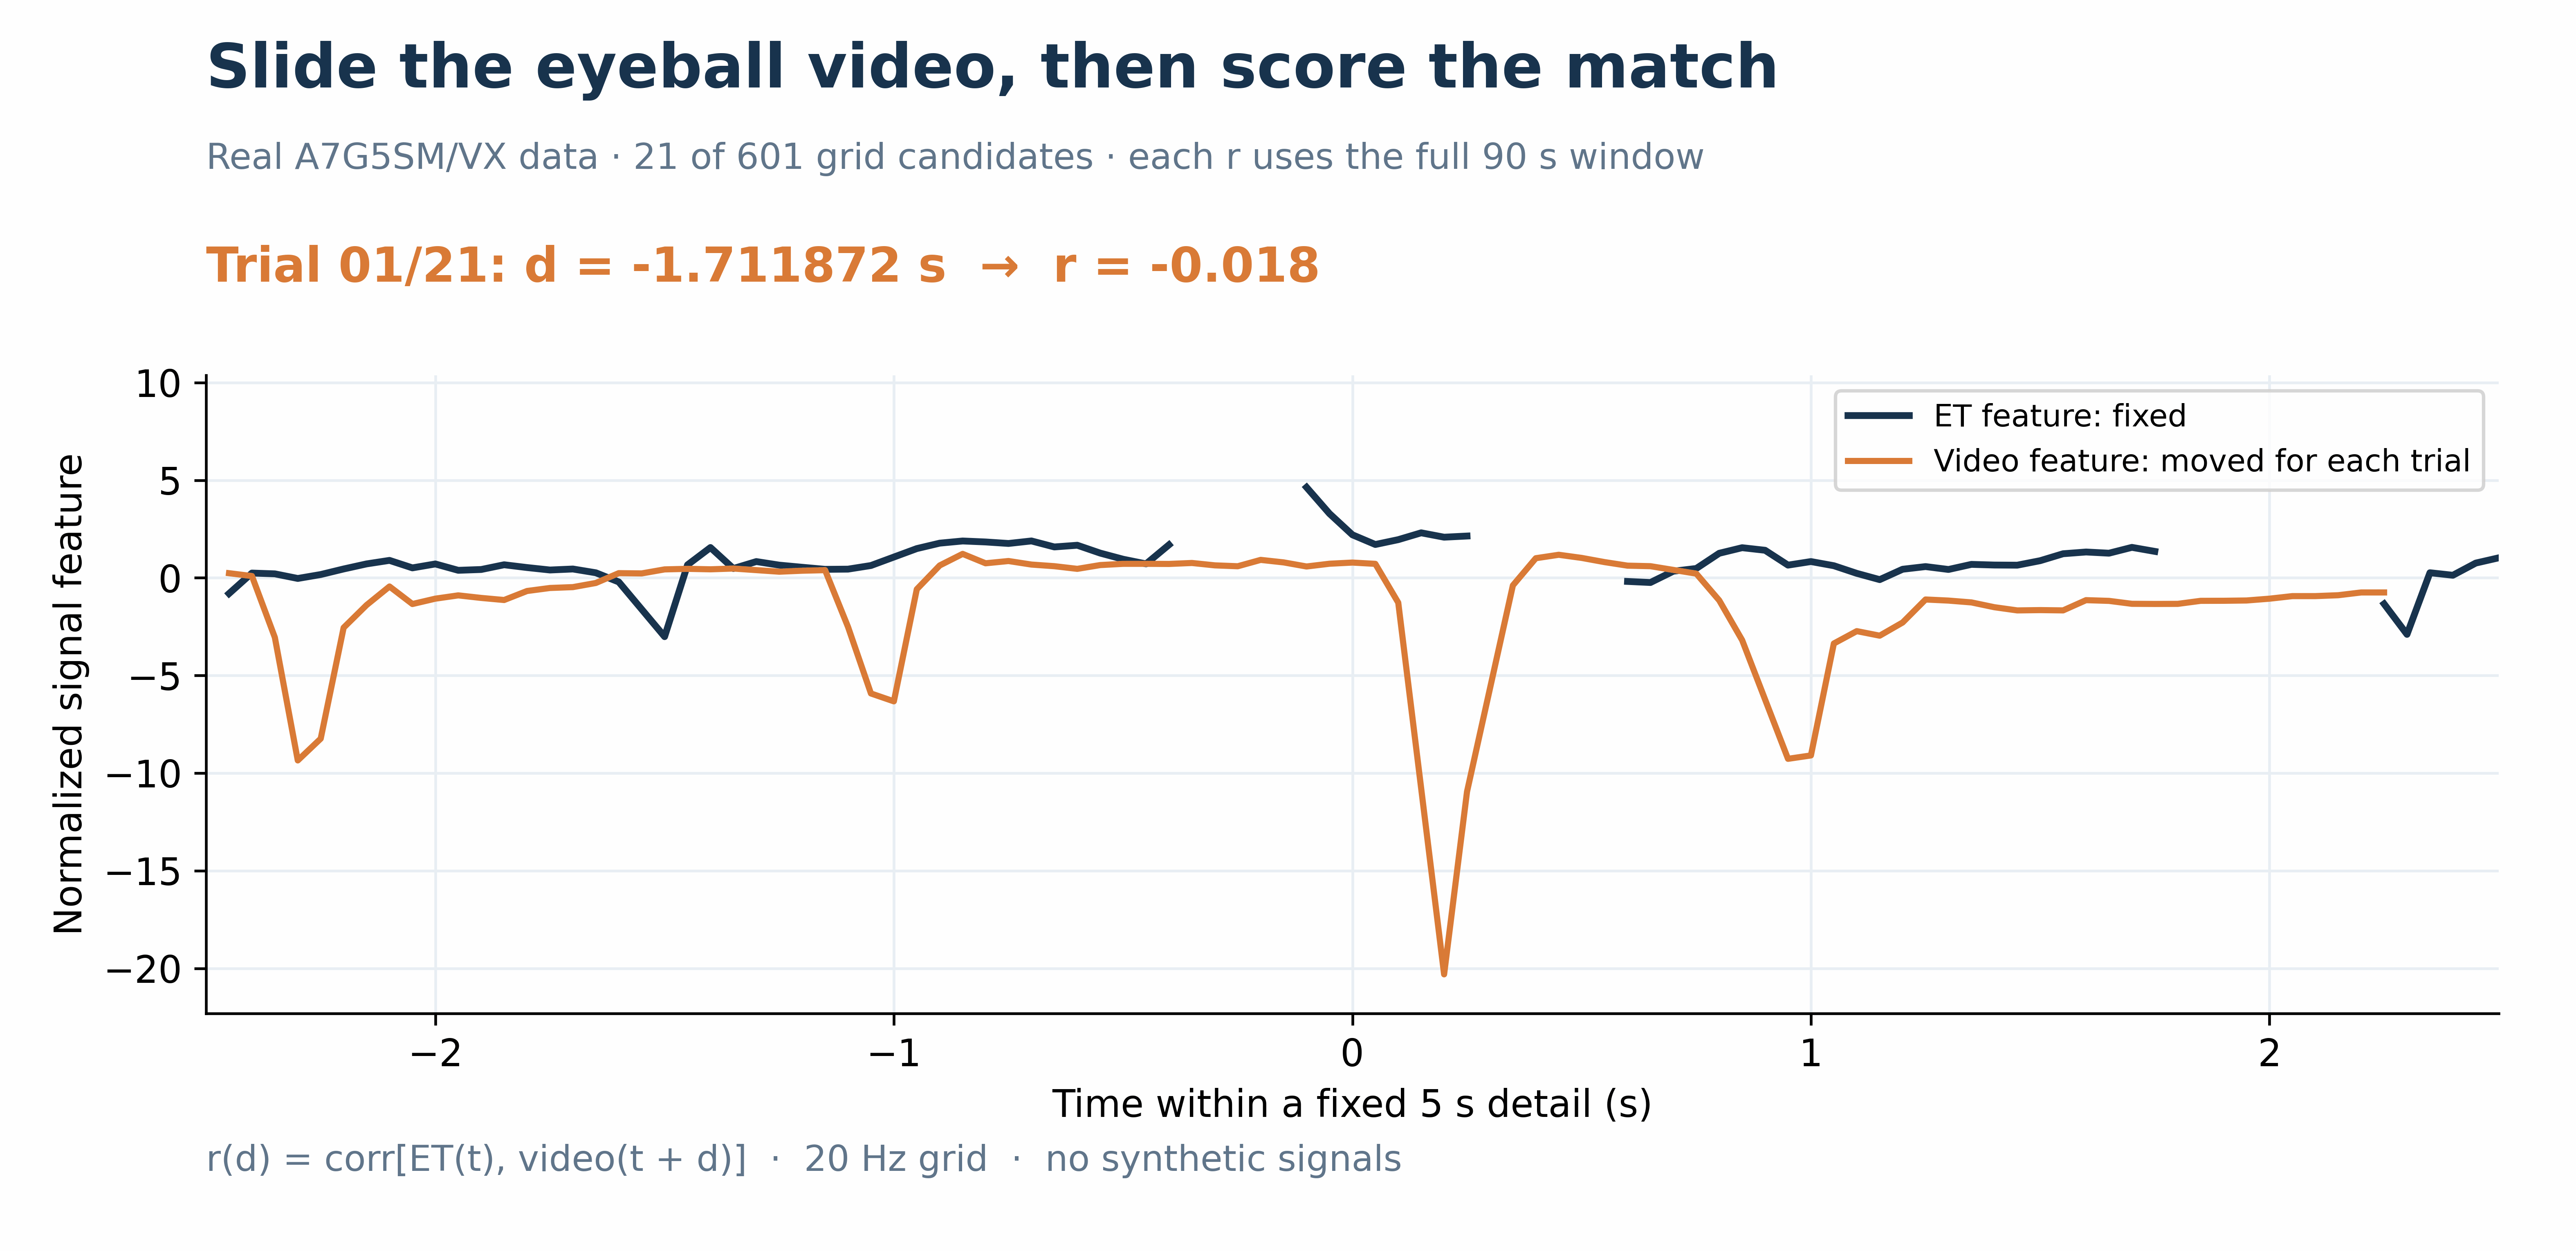

In [5]:
scan = list(range(best_lag+round(GIF_RADIUS_S*SAMPLE_HZ),
                  best_lag-round(GIF_RADIUS_S*SAMPLE_HZ)-1, -1))
INFO['n_scan'] = len(scan)
gif_fig, ax = plt.subplots(figsize=(10.5, 5.1), dpi=max(300, DPI))
gif_fig.subplots_adjust(left=.08, right=.97, bottom=.19, top=.70)
ax.plot(grid[detail]-center, et_detail, color=navy, lw=2, label=label('gif', 'et'))
video_line, = ax.plot(grid[detail]-center, shifted(scan[0])[detail], color=orange, lw=1.8,
                      label=label('gif', 'video'))
ax.set(xlim=(-DETAIL_S/2, DETAIL_S/2), ylim=matching_ylim,
       xlabel=label('gif', 'x'), ylabel=label('gif', 'y'))
ax.grid(color='#E8EEF3')
legend = ax.legend(loc='upper right', fontsize=9)
for key, y, size in [('title', .93, 18), ('subtitle', .865, 10.5), ('footer', .064, 10.5)]:
    gif_fig.text(.08, y, label('gif', key), fontsize=size, color=navy if key == 'title' else muted,
                 weight='bold' if key == 'title' else 'normal')
score_text = gif_fig.text(.08, .775, '', fontsize=14, weight='bold')
frames = []
def frame():
    gif_fig.canvas.draw()
    return PILImage.fromarray(np.asarray(gif_fig.canvas.buffer_rgba()).copy()).convert('RGB')
for i, lag in enumerate(scan, 1):
    color = teal if lag == best_lag else orange
    video_line.set_ydata(shifted(lag)[detail])
    video_line.set_color(color)
    legend.get_lines()[1].set_color(color)
    suffix = label('gif', 'grid_suffix') if lag == best_lag else ''
    score_text.set_text(label('gif', 'trial', i=i, d=prior-lag/SAMPLE_HZ, r=score(lag), suffix=suffix))
    score_text.set_color(color)
    frames.append(frame())
video_line.set_ydata(shifted(best_lag)[detail])
video_line.set_color(teal)
legend.get_lines()[1].set_color(teal)
score_text.set_text(label('gif', 'final'))
score_text.set_color(teal)
frames.append(frame())
plt.close(gif_fig)
buffer = io.BytesIO()
frames[0].save(buffer, format='GIF', save_all=True, append_images=frames[1:],
               duration=[GIF_FRAME_MS]*len(scan)+[GIF_HOLD_MS], loop=0, optimize=True)
gif_bytes = buffer.getvalue()
(OUTPUT_DIR / f'{PID}_{VISIT}_lag_search.gif').write_bytes(gif_bytes)
display(Image(data=gif_bytes, format='gif'))
